# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [5]:
df = pd.read_csv('cleaned_airbnb_data_7.csv')
print("Dataset Shape (Rows, Columns):", df.shape)
display(df.head())

Dataset Shape (Rows, Columns): (10108, 60)


,id,host_id,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_is_superhost,host_listings_count,host_has_profile_pic,host_identity_verified,...,calculated_host_listings_count_shared_rooms,reviews_per_month,minimum_nights_minmax,number_of_reviews_zscore,review_volume_category,upfront_booking_cost,availability_ratio,room_type_Hotel room,room_type_Private room,room_type_Shared room
0,934859141300145599,384892315,5.0,5.0,3.0,2.0,0.0,1.0,1.0,1.0,...,0,0.00,0.006689,-0.543102,No Reviews,183.00,0.997260,0,0,0
1,944156894640610027,13392053,12.0,3.0,2.0,10.0,0.0,1.0,0.0,1.0,...,0,0.12,0.000000,-0.506719,Low,149.00,0.986301,0,1,0
2,1634902892490996951,266329439,7.0,0.0,0.0,3.0,0.0,1.0,1.0,1.0,...,0,0.00,0.003344,-0.543102,No Reviews,1010.00,1.000000,0,0,0
3,1308737991593278409,398748229,5.0,1.0,3.0,3.0,0.0,4.0,1.0,1.0,...,0,2.39,0.000000,-0.170172,High,593.00,0.928767,0,0,0
4,574582741829434703,434308464,4.0,6.0,4.0,6.0,1.0,181.0,1.0,1.0,...,0,0.60,0.003344,-0.261130,High,557.34,0.978082,0,0,0


### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. The dataset includes Airbnb listings in Austin, and each row is one property. It has information about the host (how long they’ve been hosting, superhost status, how many listings they have), the property itself (how many guests it fits, bedrooms, bathrooms, beds, room type), location (latitude and longitude), booking rules (minimum and maximum nights), availability over the next 30 to 365 days, review activity and review scores, and the nightly price. It also has the columns I created in Assignment 7, like the scaled columns, the review volume categories, and the one-hot encoded room types.

2.There are 10,108 rows and 60 columns.

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [6]:
# 🔧 Section 2: Drop columns not useful for modeling

# Example columns from the instructions (already removed in Assignment 7, errors='ignore' skips them)
example_cols = ['post_id', 'title', 'descr', 'details', 'address']

# ID columns: just labels, no relationship to price
id_cols = ['id', 'host_id']

# Text / date columns a linear regression can't use directly
text_date_cols = ['property_type', 'review_volume_category', 'first_review', 'last_review']

# neighbourhood_cleansed is a ZIP code - looks numeric, but a bigger ZIP isn't "more" of anything
location_cols = ['neighbourhood_cleansed']

# Leakage: upfront_booking_cost = price x minimum_nights, so it contains the answer
leakage_cols = ['upfront_booking_cost']

# Duplicates: rescaled copies or combinations of other columns
duplicate_cols = ['minimum_nights_minmax',          # copy of minimum_nights
                  'number_of_reviews_zscore',       # copy of number_of_reviews
                  'availability_ratio',             # availability_365 / 365
                  'calculated_host_listings_count'] # sum of the entire/private/shared counts

cols_to_drop = example_cols + id_cols + text_date_cols + location_cols + leakage_cols + duplicate_cols
df_model = df.drop(columns=cols_to_drop, errors='ignore')

print("Shape before dropping:", df.shape)
print("Shape after dropping: ", df_model.shape)
print("\nRemaining columns:\n", list(df_model.columns))

Shape before dropping: (10108, 60)
Shape after dropping:  (10108, 48)

Remaining columns:
 ['hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_is_superhost', 'host_listings_count', 'host_has_profile_pic', 'host_identity_verified', 'latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'has_availability', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value',

### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. The example columns (post_id, title, descr, details, address) weren’t in my data anymore because I already removed text columns in Assignment 7, so I dropped a different set:
ID columns (id, host_id): these are just labels and don’t have anything to do with price.
Text and date columns (property_type, review_volume_category, first_review, last_review): linear regression can only use numbers.
neighbourhood_cleansed: in Austin this is a ZIP code. It looks like a number, but a higher ZIP code doesn’t mean “more” of anything, so the model would read it wrong.
upfront_booking_cost: I made this in Assignment 7 by multiplying price by minimum nights, so it has the price built into it.
Duplicate columns (minimum_nights_minmax, number_of_reviews_zscore, availability_ratio, calculated_host_listings_count): these are just rescaled versions or sums of other columns that are still in the data.
That left me with 48 columns: 47 features plus price.

2. If I kept upfront_booking_cost, the model would basically be cheating, because it would be using price to predict price. It would score really well on paper but would be useless for a new listing that doesn’t have a price yet. Keeping the duplicate columns would cause multicollinearity, where two columns carry the same information and the model can’t tell which one deserves the credit, so the coefficients become unreliable. And treating ZIP codes or IDs like normal numbers would just add noise and could create fake patterns.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

Correlation with price (highest to lowest):
bathrooms                                       0.615
accommodates                                    0.582
beds                                            0.561
bedrooms                                        0.559
review_scores_location                          0.096
review_scores_rating                            0.091
review_scores_cleanliness                       0.082
room_type_Hotel room                            0.079
availability_30                                 0.070
review_scores_accuracy                          0.064
availability_365                                0.062
review_scores_communication                     0.058
review_scores_checkin                           0.057
hosts_time_as_host_years                        0.055
availability_60                                 0.053
review_scores_value                             0.045
host_is_superhost                               0.038
availability_eoy                      

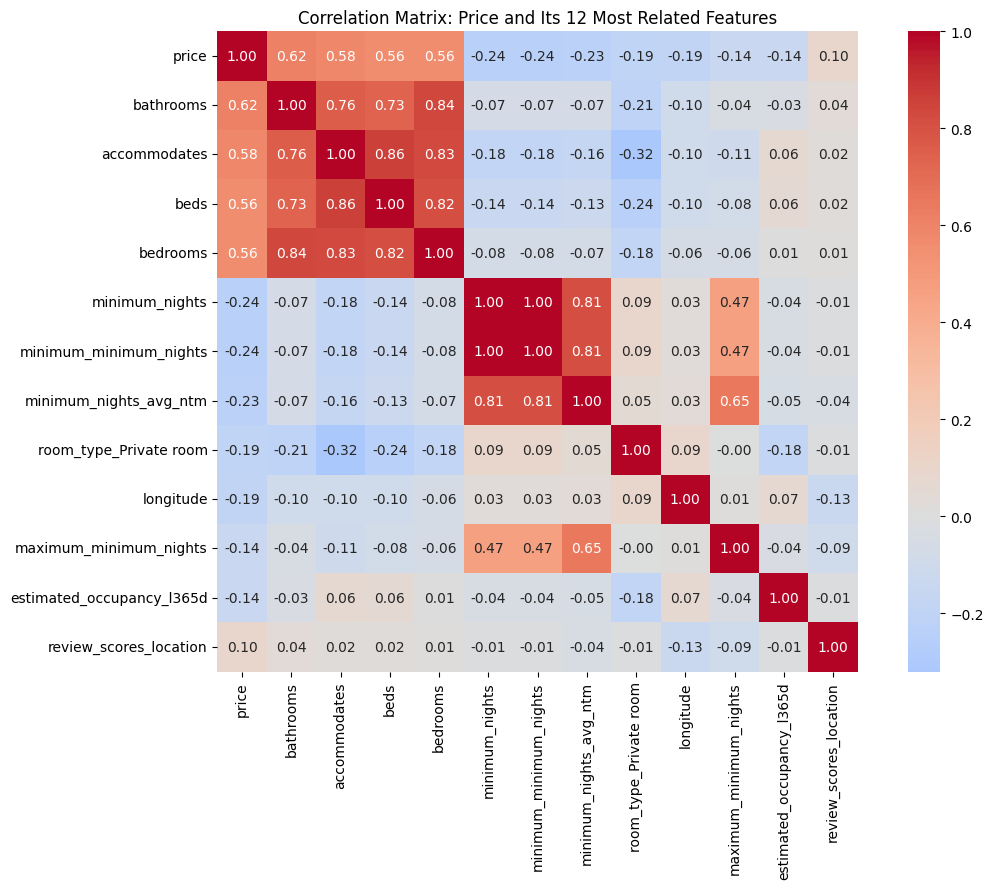

In [7]:
# 🔧 Section 3: Correlation matrix and relationships with price

corr_matrix = df_model.corr(numeric_only=True)

# Correlation of every feature with price, strongest first
price_corr = corr_matrix['price'].drop('price').sort_values(ascending=False)
print("Correlation with price (highest to lowest):")
print(price_corr.round(3))

# Heatmap of the 12 features most strongly related to price
top_features = price_corr.abs().sort_values(ascending=False).head(12).index.tolist()
plt.figure(figsize=(12, 9))
sns.heatmap(df_model[['price'] + top_features].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, square=True)
plt.title('Correlation Matrix: Price and Its 12 Most Related Features')
plt.tight_layout()
plt.show()

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. The strongest positive correlations with price were all about the size of the place: bathrooms (0.62), accommodates (0.58), beds (0.56), and bedrooms (0.56). Everything else was pretty weak by comparison. The strongest negative correlations were minimum_nights (-0.24), room_type_Private room (-0.19), longitude (-0.19), and estimated_occupancy_l365d (-0.14). So listings with long minimum stays, private rooms, and listings farther east in Austin tend to be cheaper, and the listings that get booked the most also tend to be cheaper.

2. The size variables are clearly the most useful predictors. I also noticed that bathrooms, bedrooms, beds, and accommodates are strongly correlated with each other in the heatmap, since bigger homes have more of everything, so they overlap a lot. Room type, minimum nights, location, and occupancy look useful too, even if they’re weaker on their own.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [8]:
# 🔧 Section 4: Define features (X) and target (y)

y = df_model['price']
X = df_model.drop(columns=['price'])

print("Target:", y.name)
print("Number of features:", X.shape[1])
print("Features:\n", list(X.columns))

Target: price
Number of features: 47
Features:
 ['hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_is_superhost', 'host_listings_count', 'host_has_profile_pic', 'host_identity_verified', 'latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'has_availability', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'calculated_host_listings_count_entire_homes', 'cal

### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. I’m using all 47 remaining numeric columns as features. That includes property size (accommodates, bathrooms, bedrooms, beds), room type (the three one-hot columns), location (latitude, longitude), booking rules (minimum and maximum nights), availability, review counts and review scores, and host details like superhost status and how long they’ve been hosting.

2. It’s a regression problem because price is a continuous number. I’m trying to predict an exact dollar amount, like $217 a night, not sort listings into groups. If I were predicting something like “will this listing be booked, yes or no” or “is it a budget, mid-range, or luxury listing,” that would be classification.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [11]:
# 🔧 Section 5: Split into 80% training / 20% testing

import numpy as np
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features so coefficients are comparable in Section 8
# (scaler learns from training data only)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("Training set:", X_train.shape)
print("Testing set: ", X_test.shape)

Training set: (8086, 47)
Testing set:  (2022, 47)


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [12]:
# 🔧 Section 6: Fit the linear regression model and predict

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

comparison = pd.DataFrame({'Actual Price': y_test.values[:10],
                           'Predicted Price': y_pred[:10].round(2)})
display(comparison)

,Actual Price,Predicted Price
0,234.40,244.46
1,164.33,138.39
2,639.22,975.36
3,192.75,418.13
4,382.00,408.52
5,94.00,173.42
6,200.59,462.51
7,130.67,138.58
8,253.56,478.54
9,40.91,-53.05


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [13]:
# 🔧 Section 7: Evaluate model performance

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}  <- typical prediction error in dollars")
print(f"R² Score: {r2:.4f}")
print(f"\nFor reference, the average price in the test set is ${y_test.mean():,.2f}")

Mean Squared Error (MSE): 44,529.98
Root Mean Squared Error (RMSE): $211.02  <- typical prediction error in dollars
R² Score: 0.4977

For reference, the average price in the test set is $306.40


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. My R² is 0.498, so the model explains about 50% of the variation in nightly prices. That’s a decent start, since it shows the features really are related to price, but half of what drives price is still unexplained. That’s probably because the model can’t see things like amenities, photos, how nice the place is, or the exact neighborhood.

2. My MSE is 44,530, but that number is in “squared dollars,” so it’s hard to interpret on its own. Taking the square root gives an RMSE of about $211, which means my predictions are usually off by around $211. The average price is $306, so that’s a pretty big error. To improve it, I could predict the log of price instead, since price is very right-skewed (which I saw in Assignment 7) and a few expensive listings pull the model around. I could also add neighborhood as one-hot columns, turn the amenities list into features, or try a model that handles non-linear patterns, like a random forest.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [14]:
# 🔧 Section 8: Coefficient table, most impactful features first

coef_table = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_})
coef_table['Abs_Coefficient'] = coef_table['Coefficient'].abs()
coef_table = coef_table.sort_values(by='Abs_Coefficient', ascending=False).reset_index(drop=True)

# Each coefficient = change in price ($) for a one-standard-deviation increase in that feature
display(coef_table[['Feature', 'Coefficient']].round(2))

,Feature,Coefficient
0,bathrooms,119.27
1,accommodates,43.87
2,estimated_occupancy_l365d,-37.46
3,review_scores_value,-36.62
4,room_type_Hotel room,31.95
5,beds,31.56
6,review_scores_rating,29.33
7,longitude,-27.59
8,host_listings_count,-24.16
9,review_scores_location,23.24


### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. I scaled all the features before fitting, so each coefficient means "how many dollars price changes when this feature goes up by one standard deviation, holding everything else the same." That lets me compare them fairly. Bathrooms had by far the biggest positive effect (+119 dollars), followed by accommodates (+44 dollars), room_type_Hotel room (+32 dollars), beds (+32 dollars), and review_scores_rating (+29 dollars).

2. Yes, a few were surprisingly negative. Estimated_occupancy_l365d was -37 dollars, meaning the listings booked the most nights are cheaper. I think this is because cheaper listings get booked more often, not that bookings lower the price. Review_scores_value was also -37 dollars, because guests rate "value" lower when they paid more, which makes sense once I think about it. Bedrooms came out slightly negative (-5 dollars) even though it had a strong positive correlation with price. This is multicollinearity, because bathrooms, beds, and accommodates already capture most of the same "size" information. Host_listings_count was -24 dollars, so hosts with lots of listings, like property management companies, tend to charge less per listing.

3. The biggest takeaway is that size and capacity drive price way more than anything else. For a host, adding a bathroom or setting the place up to sleep more guests is the clearest way to justify a higher price. The occupancy result also shows the tradeoff hosts face: pricing lower gets more bookings, and pricing higher gets fewer. Overall rating still adds value too, so keeping reviews high matters.

## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [15]:
# 🔧 Section 9: Refined model with the top 5 features

top_5 = coef_table['Feature'].head(5).tolist()
print("Features in the refined model:", top_5)

refined_model = LinearRegression()
refined_model.fit(X_train_scaled[top_5], y_train)
y_pred_refined = refined_model.predict(X_test_scaled[top_5])

mse_refined = mean_squared_error(y_test, y_pred_refined)
r2_refined = r2_score(y_test, y_pred_refined)

results = pd.DataFrame({
    'Model': [f'Baseline ({X.shape[1]} features)', 'Refined (top 5 features)'],
    'MSE': [round(mse, 2), round(mse_refined, 2)],
    'RMSE ($)': [round(np.sqrt(mse), 2), round(np.sqrt(mse_refined), 2)],
    'R²': [round(r2, 4), round(r2_refined, 4)]
})
display(results)

display(pd.DataFrame({'Feature': top_5, 'Coefficient': refined_model.coef_.round(2)}))

Features in the refined model: ['bathrooms', 'accommodates', 'estimated_occupancy_l365d', 'review_scores_value', 'room_type_Hotel room']


,Model,MSE,RMSE ($),R²
0,Baseline (47 features),44529.98,211.02,0.4977
1,Refined (top 5 features),49950.09,223.50,0.4365


,Feature,Coefficient
0,bathrooms,117.43
1,accommodates,84.70
2,estimated_occupancy_l365d,-40.74
3,review_scores_value,5.57
4,room_type_Hotel room,31.83


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1. I kept the 5 features with the largest absolute coefficients: bathrooms, accommodates, estimated_occupancy_l365d, review_scores_value, and room_type_Hotel room. I picked them because they had the strongest effect on price in the baseline model, so in theory they should carry most of the predictive power.

2. No, performance went down. R² dropped from 0.498 to 0.437, and RMSE went up from 211 dollars to 224 dollars. I think this happened because the other 42 features still added real information that the model lost, like beds, location, minimum nights, and the private room column. The 5 features also don't work the same way on their own. For example, review_scores_value went from -37 dollars to just +6 dollars once the other review scores were removed, which shows its big coefficient was partly offsetting the other review columns rather than being important on its own.

3. I would recommend the baseline model if the goal is accuracy, since it explains more of the price and makes smaller errors. But the refined model is much easier to explain to a host. With only 5 features, I could say "your bathrooms, guest capacity, and room type are what set your price," and it's still only about 12 dollars less accurate on average. If I were presenting to non-technical stakeholders, I would use the refined model to explain what matters and keep the baseline model for the actual predictions.

4. This assignment connects to my learning outcome because it's the first time I took data all the way from raw listings, through cleaning and transforming it, to a model that actually makes predictions and gives business insights. Since I'm a finance major interested in commercial real estate, figuring out what drives a property's price and how to explain it to a decision-maker is exactly the kind of analysis I want to be able to do.


## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. My model answered the question: what drives the nightly price of an Airbnb listing in Austin, and can I predict it? It showed that property size (especially bathrooms and how many guests it fits) and room type matter most, and that I can predict about half of the variation in price, with a typical error of around 211 dollars.

2. For hosts, I'd recommend focusing on capacity. Adding a bathroom or setting the space up to sleep more guests is the clearest path to a higher price. Entire homes earn much more than private rooms. Hosts should also understand the price vs. occupancy tradeoff, since cheaper listings get booked more, so they should price to fill the nights they want rather than just going as high as possible. For Airbnb, a model like this could power a "suggested price" tool for new hosts, especially people who have no idea where to start.

3. Next, I would predict the log of price to handle the skew, add neighborhood as one-hot columns since location clearly matters (longitude was one of the stronger correlations), turn the amenities list into features like pool, hot tub, or parking, and try models like a random forest that can pick up non-linear patterns. I'd also use cross-validation instead of a single train/test split to make sure the results hold up.

4. This ties into my learning outcome because I can now go beyond just running code and actually explain what the model means for a real business decision. That's really the core skill in business analytics. Being able to value a property and explain the reasoning behind it is also what I'll need to do in commercial real estate, so this felt directly applicable.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [4]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"

[NbConvertApp] Converting notebook assignment_11_regression.ipynb to html
[NbConvertApp] Writing 311614 bytes to assignment_11_regression.html
